# Tugas Praktikum 4 - Clustering
**Nama:** Siti Nikmatus Sholihah  
**NIM:** 244107020014

---
---
# BAGIAN 1: TUGAS K-MEANS
---
---

## Import Library yang Diperlukan

In [1]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Set style untuk visualisasi
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

---
## SOAL 1: Gunakan data 'Mall_Customers.csv'
---

In [3]:
# Load dataset
df = pd.read_csv('../Data Praktikum/Mall_Customers.csv')

# Tampilkan 5 baris pertama
print("5 Baris Pertama Data:")
print(df.head())
print("\nInformasi Dataset:")
print(df.info())
print("\nStatistik Deskriptif:")
print(df.describe())

5 Baris Pertama Data:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB
None

Statistik Deskriptif:
       C

### 1.2 Seleksi Fitur untuk Clustering

Fitur yang dipilih untuk clustering:
- **Annual Income (k$)**: Pendapatan tahunan pelanggan
- **Spending Score (1-100)**: Skor pengeluaran pelanggan

Kedua fitur ini dipilih karena sangat relevan untuk segmentasi pelanggan dalam konteks bisnis retail.

In [4]:
# Pilih fitur untuk clustering
# Menggunakan Annual Income dan Spending Score
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

print("Shape data yang akan di-cluster:", X.shape)
print("\nContoh data:")
print(X[:5])

Shape data yang akan di-cluster: (200, 2)

Contoh data:
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


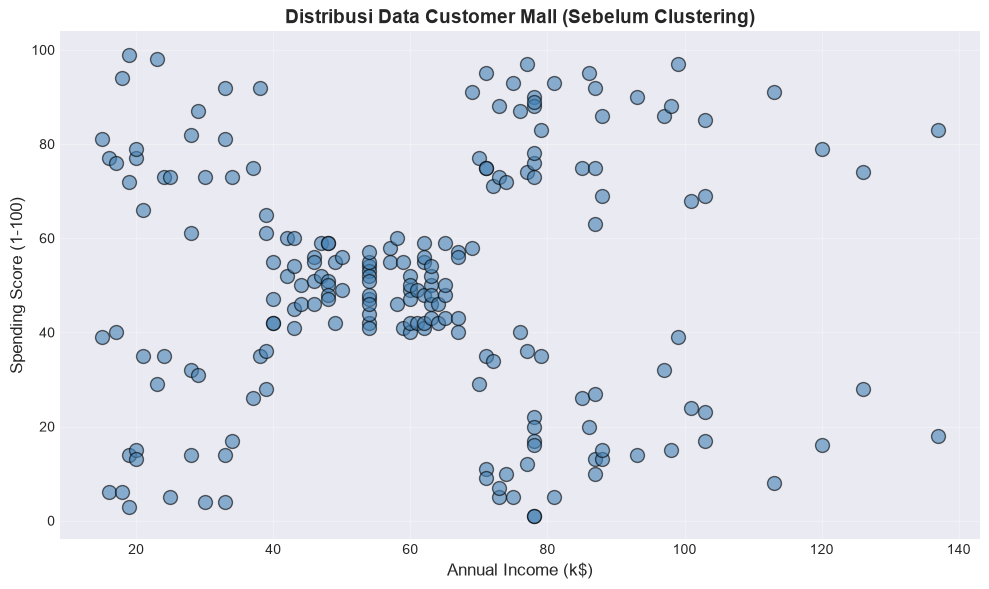

In [5]:
# Visualisasi data sebelum clustering
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c='steelblue', s=100, alpha=0.6, edgecolors='black')
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.title('Distribusi Data Customer Mall (Sebelum Clustering)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3 Menentukan Jumlah Cluster Optimal dengan Elbow Method

d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

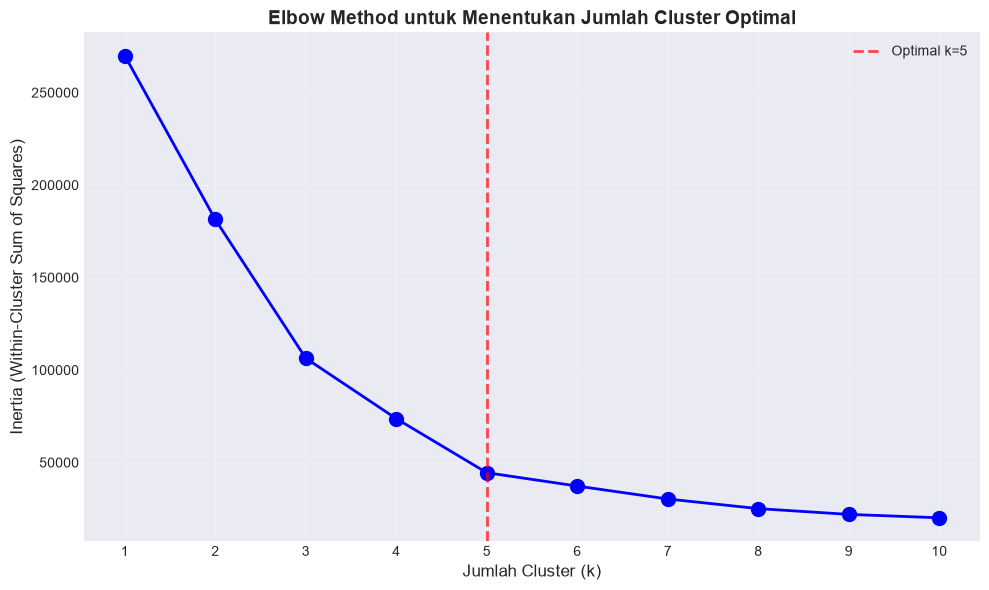


Inertia untuk setiap nilai k:
k=1: 269981.28
k=2: 181363.60
k=3: 106348.37
k=4: 73679.79
k=5: 44448.46
k=6: 37233.81
k=7: 30241.34
k=8: 25036.42
k=9: 21916.79
k=10: 20072.07


In [6]:
# Mencari nilai K optimal menggunakan Elbow Method
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertia, 'bo-', linewidth=2, markersize=10)
plt.xlabel('Jumlah Cluster (k)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.title('Elbow Method untuk Menentukan Jumlah Cluster Optimal', fontsize=14, fontweight='bold')
plt.xticks(K_range)
plt.grid(True, alpha=0.3)

# Highlight titik elbow (k=5)
plt.axvline(x=5, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Optimal k=5')
plt.legend()
plt.tight_layout()
plt.show()

print("\nInertia untuk setiap nilai k:")
for k, iner in zip(K_range, inertia):
    print(f"k={k}: {iner:.2f}")

### 1.4 Membuat Model K-Means dengan K Optimal

Dari Elbow Method, terlihat bahwa **k=5** adalah jumlah cluster yang optimal karena:
- Penurunan inertia mulai melambat setelah k=5
- Membentuk "siku" pada grafik

In [7]:
# Membuat model K-Means dengan k=5
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)

print(f"Model K-Means dengan k={optimal_k} berhasil dibuat")
print(f"\nCentroids:")
print(kmeans.cluster_centers_)
print(f"\nInertia: {kmeans.inertia_:.2f}")
print(f"\nJumlah customer per cluster:")
for i in range(optimal_k):
    print(f"Cluster {i}: {np.sum(y_kmeans == i)} customers")

Model K-Means dengan k=5 berhasil dibuat

Centroids:
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]

Inertia: 44448.46

Jumlah customer per cluster:
Cluster 0: 81 customers
Cluster 1: 39 customers
Cluster 2: 22 customers
Cluster 3: 35 customers
Cluster 4: 23 customers


d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


### 1.5 Visualisasi Hasil Clustering

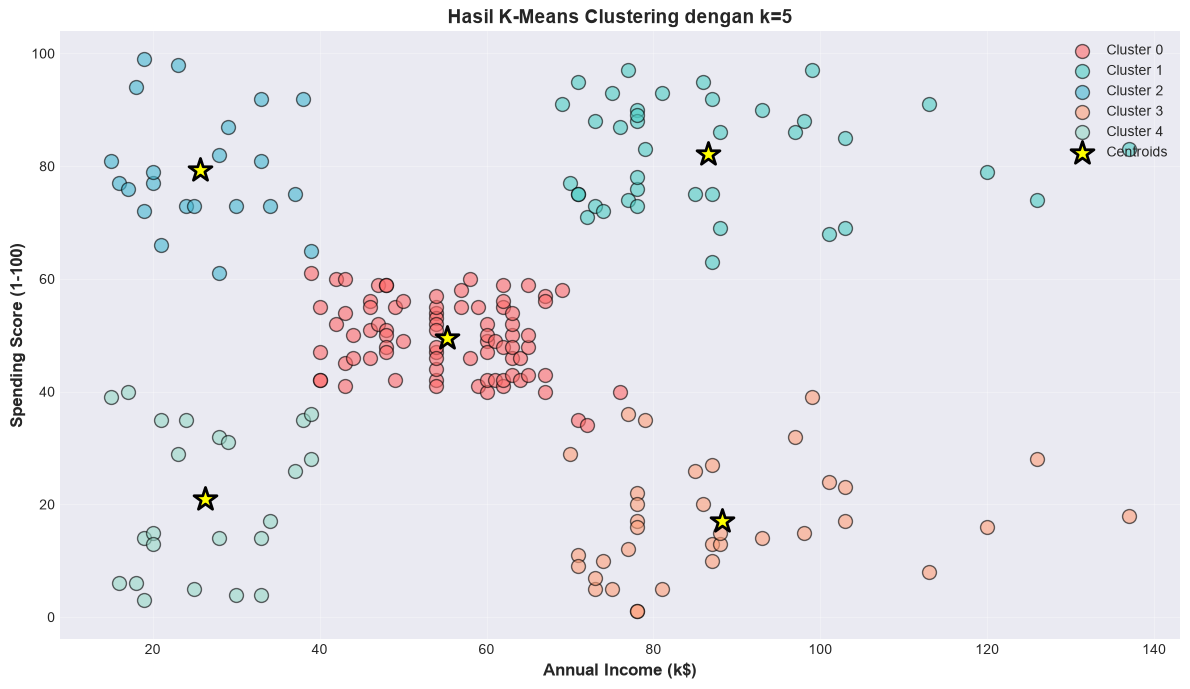

In [8]:
# Visualisasi hasil clustering
plt.figure(figsize=(12, 7))

# Plot setiap cluster dengan warna berbeda
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
for i in range(optimal_k):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], 
                s=100, c=colors[i], label=f'Cluster {i}', 
                alpha=0.6, edgecolors='black', linewidth=1)

# Plot centroids
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=300, c='yellow', marker='*', edgecolors='black', 
            linewidth=2, label='Centroids', zorder=5)

plt.xlabel('Annual Income (k$)', fontsize=12, fontweight='bold')
plt.ylabel('Spending Score (1-100)', fontsize=12, fontweight='bold')
plt.title(f'Hasil K-Means Clustering dengan k={optimal_k}', fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 1.6 Interpretasi Hasil Clustering

In [9]:
# Analisis karakteristik setiap cluster
df_clustered = df.copy()
df_clustered['Cluster'] = y_kmeans

print("Karakteristik Setiap Cluster:\n")
print("="*80)

for i in range(optimal_k):
    cluster_data = df_clustered[df_clustered['Cluster'] == i]
    avg_income = cluster_data['Annual Income (k$)'].mean()
    avg_spending = cluster_data['Spending Score (1-100)'].mean()
    count = len(cluster_data)
    
    print(f"\nCluster {i}:")
    print(f"  - Jumlah Customer: {count}")
    print(f"  - Rata-rata Income: ${avg_income:.2f}k")
    print(f"  - Rata-rata Spending Score: {avg_spending:.2f}")
    
    # Interpretasi bisnis
    if avg_income < 50 and avg_spending < 50:
        category = "Low Income, Low Spending (Careful Shoppers)"
    elif avg_income < 50 and avg_spending >= 50:
        category = "Low Income, High Spending (Aspiring Shoppers)"
    elif avg_income >= 50 and avg_spending < 50:
        category = "High Income, Low Spending (Conservative Shoppers)"
    elif avg_income >= 50 and avg_spending >= 50:
        category = "High Income, High Spending (Target Customers)"
    else:
        category = "Moderate Shoppers"
    
    print(f"  - Kategori: {category}")
    print("-"*80)

Karakteristik Setiap Cluster:


Cluster 0:
  - Jumlah Customer: 81
  - Rata-rata Income: $55.30k
  - Rata-rata Spending Score: 49.52
  - Kategori: High Income, Low Spending (Conservative Shoppers)
--------------------------------------------------------------------------------

Cluster 1:
  - Jumlah Customer: 39
  - Rata-rata Income: $86.54k
  - Rata-rata Spending Score: 82.13
  - Kategori: High Income, High Spending (Target Customers)
--------------------------------------------------------------------------------

Cluster 2:
  - Jumlah Customer: 22
  - Rata-rata Income: $25.73k
  - Rata-rata Spending Score: 79.36
  - Kategori: Low Income, High Spending (Aspiring Shoppers)
--------------------------------------------------------------------------------

Cluster 3:
  - Jumlah Customer: 35
  - Rata-rata Income: $88.20k
  - Rata-rata Spending Score: 17.11
  - Kategori: High Income, Low Spending (Conservative Shoppers)
----------------------------------------------------------------------

---
## 2. Tugas DBSCAN

1. Buat dataset *make_moons* (1000 sampel, noise=0.05), lalu normalisasi.
2. Jalankan DBSCAN dengan `eps=0.2`, `min_samples=5`, hitung jumlah klaster & noise.
3. Evaluasi dengan metrik: Homogeneity, Completeness, V-measure, ARI, AMI, Silhouette.
4. Visualisasikan hasil DBSCAN (core sample = titik besar, non-core = titik kecil, noise = hitam).
5. Lakukan eksperimen dengan variasi parameter dan catat perubahan klaster, noise, dan kualitas evaluasi.

In [11]:
# Import library tambahan untuk DBSCAN
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

### 2.1 Membuat dan Normalisasi Dataset make_moons

In [12]:
# Buat dataset make_moons
X_moons, y_true = make_moons(n_samples=1000, noise=0.05, random_state=42)

print("Dataset make_moons telah dibuat")
print(f"Shape: {X_moons.shape}")
print(f"Jumlah sampel: {X_moons.shape[0]}")
print(f"Jumlah fitur: {X_moons.shape[1]}")
print(f"\nContoh data sebelum normalisasi:")
print(X_moons[:5])

Dataset make_moons telah dibuat
Shape: (1000, 2)
Jumlah sampel: 1000
Jumlah fitur: 2

Contoh data sebelum normalisasi:
[[-0.02137124  0.40618608]
 [ 0.97670045 -0.45832306]
 [ 0.90405882 -0.37651952]
 [ 0.37736316 -0.39703717]
 [-0.84192557  0.53058695]]


In [13]:
# Normalisasi data
scaler = StandardScaler()
X_moons_scaled = scaler.fit_transform(X_moons)

print("Data telah dinormalisasi")
print(f"\nContoh data setelah normalisasi:")
print(X_moons_scaled[:5])
print(f"\nMean: {X_moons_scaled.mean(axis=0)}")
print(f"Std: {X_moons_scaled.std(axis=0)}")

Data telah dinormalisasi

Contoh data setelah normalisasi:
[[-0.59996716  0.31757343]
 [ 0.55020965 -1.42528284]
 [ 0.46649751 -1.26036633]
 [-0.14046604 -1.30173005]
 [-1.54557314  0.56836644]]

Mean: [-2.53075338e-16 -3.20854454e-16]
Std: [1. 1.]


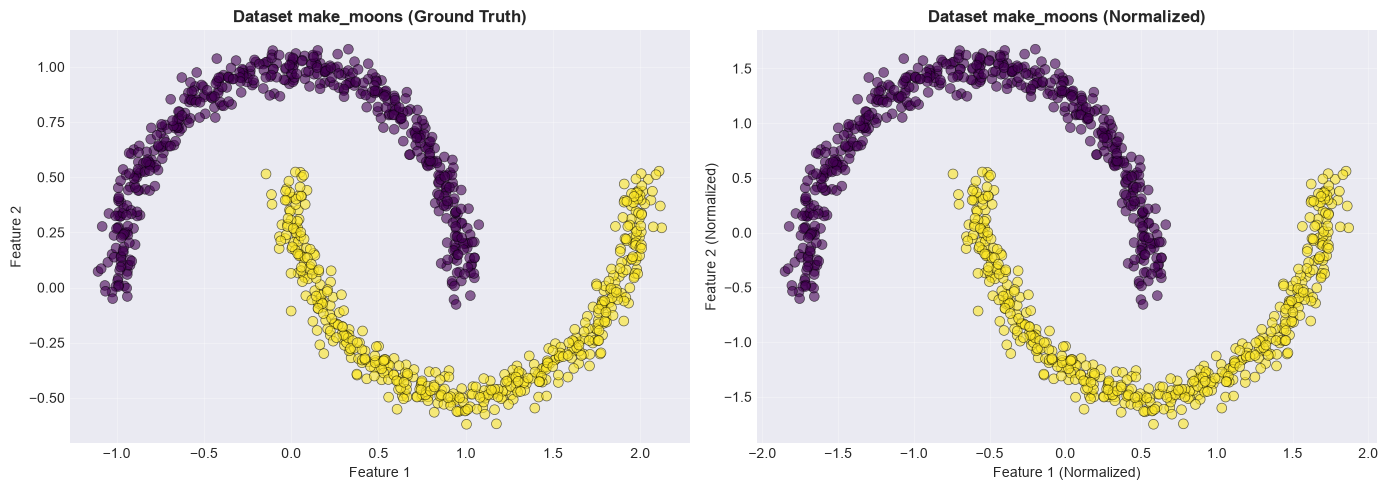

In [14]:
# Visualisasi dataset make_moons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot data asli (ground truth)
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_true, cmap='viridis', 
                s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].set_title('Dataset make_moons (Ground Truth)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
axes[0].grid(True, alpha=0.3)

# Plot data setelah normalisasi
axes[1].scatter(X_moons_scaled[:, 0], X_moons_scaled[:, 1], c=y_true, cmap='viridis', 
                s=50, alpha=0.6, edgecolors='black', linewidth=0.5)
axes[1].set_title('Dataset make_moons (Normalized)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Feature 1 (Normalized)')
axes[1].set_ylabel('Feature 2 (Normalized)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.2 DBSCAN dengan Parameter Default (eps=0.2, min_samples=5)

In [15]:
# Jalankan DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_dbscan = dbscan.fit_predict(X_moons_scaled)

# Hitung jumlah cluster dan noise
n_clusters = len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0)
n_noise = list(y_dbscan).count(-1)

print("Hasil DBSCAN (eps=0.2, min_samples=5):")
print("="*60)
print(f"Jumlah cluster yang ditemukan: {n_clusters}")
print(f"Jumlah noise points: {n_noise}")
print(f"Persentase noise: {n_noise/len(X_moons_scaled)*100:.2f}%")
print(f"\nLabel cluster yang ditemukan: {set(y_dbscan)}")

Hasil DBSCAN (eps=0.2, min_samples=5):
Jumlah cluster yang ditemukan: 2
Jumlah noise points: 0
Persentase noise: 0.00%

Label cluster yang ditemukan: {np.int64(0), np.int64(1)}


### 2.3 Evaluasi dengan Berbagai Metrik

In [16]:
# Fungsi untuk evaluasi clustering
def evaluate_clustering(X, y_true, y_pred, title=""):
    """
    Evaluasi hasil clustering dengan berbagai metrik
    """
    # Filter noise points untuk beberapa metrik
    mask = y_pred != -1
    X_filtered = X[mask]
    y_true_filtered = y_true[mask]
    y_pred_filtered = y_pred[mask]
    
    print(f"\n{title}")
    print("="*60)
    
    # Metrik dengan ground truth
    if len(set(y_pred_filtered)) > 1:
        homogeneity = metrics.homogeneity_score(y_true_filtered, y_pred_filtered)
        completeness = metrics.completeness_score(y_true_filtered, y_pred_filtered)
        v_measure = metrics.v_measure_score(y_true_filtered, y_pred_filtered)
        ari = metrics.adjusted_rand_score(y_true_filtered, y_pred_filtered)
        ami = metrics.adjusted_mutual_info_score(y_true_filtered, y_pred_filtered)
        
        print(f"Homogeneity Score:       {homogeneity:.4f}")
        print(f"Completeness Score:      {completeness:.4f}")
        print(f"V-Measure Score:         {v_measure:.4f}")
        print(f"Adjusted Rand Index:     {ari:.4f}")
        print(f"Adjusted Mutual Info:    {ami:.4f}")
    
    # Silhouette Score (hanya untuk data tanpa noise)
    if len(set(y_pred_filtered)) > 1 and len(X_filtered) > 1:
        silhouette = metrics.silhouette_score(X_filtered, y_pred_filtered)
        print(f"Silhouette Score:        {silhouette:.4f}")
    else:
        print(f"Silhouette Score:        N/A (insufficient clusters)")
    
    return {
        'homogeneity': homogeneity if len(set(y_pred_filtered)) > 1 else 0,
        'completeness': completeness if len(set(y_pred_filtered)) > 1 else 0,
        'v_measure': v_measure if len(set(y_pred_filtered)) > 1 else 0,
        'ari': ari if len(set(y_pred_filtered)) > 1 else 0,
        'ami': ami if len(set(y_pred_filtered)) > 1 else 0,
        'silhouette': silhouette if len(set(y_pred_filtered)) > 1 and len(X_filtered) > 1 else 0
    }

# Evaluasi hasil DBSCAN
metrics_default = evaluate_clustering(X_moons_scaled, y_true, y_dbscan, 
                                      "Evaluasi DBSCAN (eps=0.2, min_samples=5)")


Evaluasi DBSCAN (eps=0.2, min_samples=5)
Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjusted Mutual Info:    1.0000
Silhouette Score:        0.3912


### 2.4 Visualisasi Hasil DBSCAN

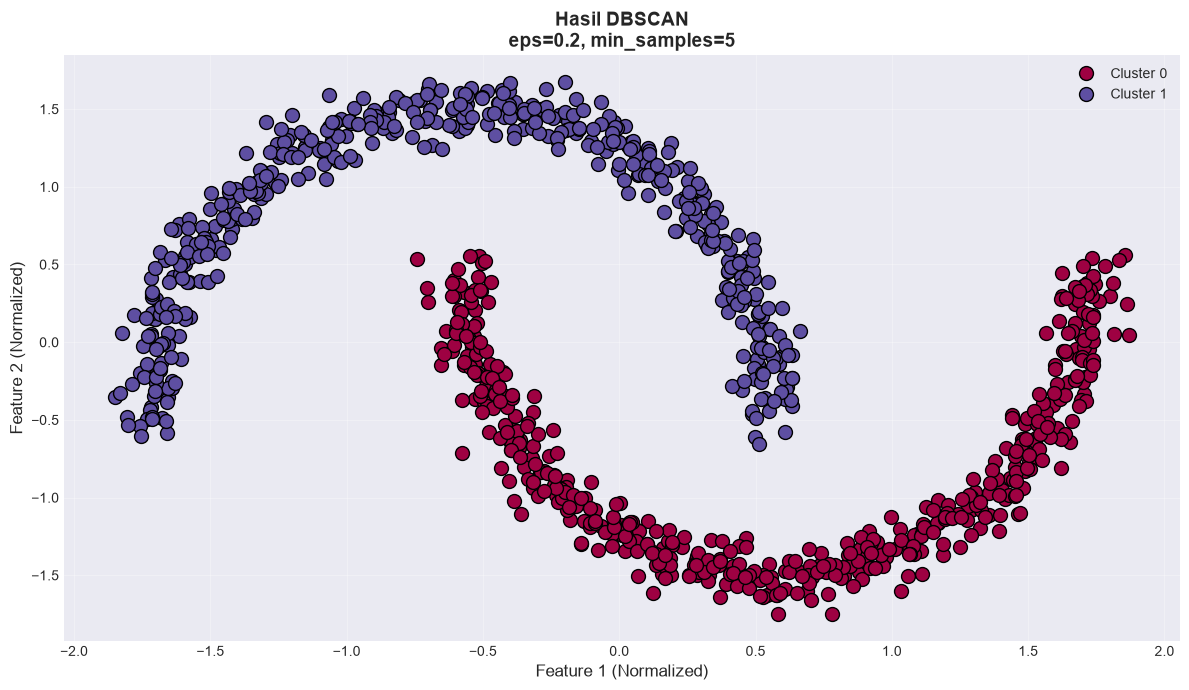

In [17]:
# Fungsi untuk visualisasi DBSCAN
def plot_dbscan(X, labels, core_samples_mask, title="", eps=None, min_samples=None):
    """
    Visualisasi hasil DBSCAN dengan core samples dan noise
    """
    plt.figure(figsize=(12, 7))
    
    # Warna untuk cluster
    unique_labels = set(labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            # Noise points berwarna hitam
            col = [0, 0, 0, 1]
        
        class_member_mask = (labels == k)
        
        # Core samples (titik besar)
        xy = X[class_member_mask & core_samples_mask]
        plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='black', markersize=10, 
                 label=f'Cluster {k}' if k != -1 else 'Noise')
        
        # Non-core samples (titik kecil)
        xy = X[class_member_mask & ~core_samples_mask]
        plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                 markeredgecolor='black', markersize=4, alpha=0.5)
    
    param_text = f"\neps={eps}, min_samples={min_samples}" if eps and min_samples else ""
    plt.title(f'{title}{param_text}', fontsize=14, fontweight='bold')
    plt.xlabel('Feature 1 (Normalized)', fontsize=12)
    plt.ylabel('Feature 2 (Normalized)', fontsize=12)
    plt.legend(loc='best', fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Identifikasi core samples
core_samples_mask = np.zeros_like(y_dbscan, dtype=bool)
core_samples_mask[dbscan.core_sample_indices_] = True

# Visualisasi
plot_dbscan(X_moons_scaled, y_dbscan, core_samples_mask, 
            "Hasil DBSCAN", eps=0.2, min_samples=5)

### 2.5 Eksperimen dengan Variasi Parameter

Melakukan eksperimen dengan variasi:
- **eps**: 0.05, 0.1, 0.3, 0.5
- **min_samples**: 3, 10, 20

In [18]:
# Eksperimen dengan variasi eps
print("\n" + "="*80)
print("EKSPERIMEN 1: VARIASI EPS (min_samples=5)")
print("="*80)

eps_values = [0.05, 0.1, 0.3, 0.5]
results_eps = []

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    y_pred = dbscan.fit_predict(X_moons_scaled)
    
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
    n_noise = list(y_pred).count(-1)
    
    print(f"\n--- eps={eps} ---")
    print(f"Jumlah cluster: {n_clusters}")
    print(f"Jumlah noise: {n_noise} ({n_noise/len(X_moons_scaled)*100:.1f}%)")
    
    # Evaluasi
    metrics_result = evaluate_clustering(X_moons_scaled, y_true, y_pred, "")
    
    results_eps.append({
        'eps': eps,
        'min_samples': 5,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'noise_pct': n_noise/len(X_moons_scaled)*100,
        **metrics_result
    })


EKSPERIMEN 1: VARIASI EPS (min_samples=5)

--- eps=0.05 ---
Jumlah cluster: 61
Jumlah noise: 386 (38.6%)


Homogeneity Score:       1.0000
Completeness Score:      0.1736
V-Measure Score:         0.2958
Adjusted Rand Index:     0.0385
Adjusted Mutual Info:    0.2794
Silhouette Score:        0.5017

--- eps=0.1 ---
Jumlah cluster: 3
Jumlah noise: 19 (1.9%)


Homogeneity Score:       1.0000
Completeness Score:      0.6932
V-Measure Score:         0.8188
Adjusted Rand Index:     0.7881
Adjusted Mutual Info:    0.8186
Silhouette Score:        0.3778

--- eps=0.3 ---
Jumlah cluster: 2
Jumlah noise: 0 (0.0%)


Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjusted Mutual Info:    1.0000
Silhouette Score:        0.3912

--- eps=0.5 ---
Jumlah cluster: 2
Jumlah noise: 0 (0.0%)


Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjuste

In [19]:
# Eksperimen dengan variasi min_samples
print("\n" + "="*80)
print("EKSPERIMEN 2: VARIASI MIN_SAMPLES (eps=0.2)")
print("="*80)

min_samples_values = [3, 10, 20]
results_min_samples = []

for min_samp in min_samples_values:
    dbscan = DBSCAN(eps=0.2, min_samples=min_samp)
    y_pred = dbscan.fit_predict(X_moons_scaled)
    
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
    n_noise = list(y_pred).count(-1)
    
    print(f"\n--- min_samples={min_samp} ---")
    print(f"Jumlah cluster: {n_clusters}")
    print(f"Jumlah noise: {n_noise} ({n_noise/len(X_moons_scaled)*100:.1f}%)")
    
    # Evaluasi
    metrics_result = evaluate_clustering(X_moons_scaled, y_true, y_pred, "")
    
    results_min_samples.append({
        'eps': 0.2,
        'min_samples': min_samp,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'noise_pct': n_noise/len(X_moons_scaled)*100,
        **metrics_result
    })


EKSPERIMEN 2: VARIASI MIN_SAMPLES (eps=0.2)

--- min_samples=3 ---
Jumlah cluster: 2
Jumlah noise: 0 (0.0%)


Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjusted Mutual Info:    1.0000
Silhouette Score:        0.3912

--- min_samples=10 ---
Jumlah cluster: 2
Jumlah noise: 0 (0.0%)


Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjusted Mutual Info:    1.0000
Silhouette Score:        0.3912

--- min_samples=20 ---
Jumlah cluster: 2
Jumlah noise: 3 (0.3%)


Homogeneity Score:       1.0000
Completeness Score:      1.0000
V-Measure Score:         1.0000
Adjusted Rand Index:     1.0000
Adjusted Mutual Info:    1.0000
Silhouette Score:        0.3953


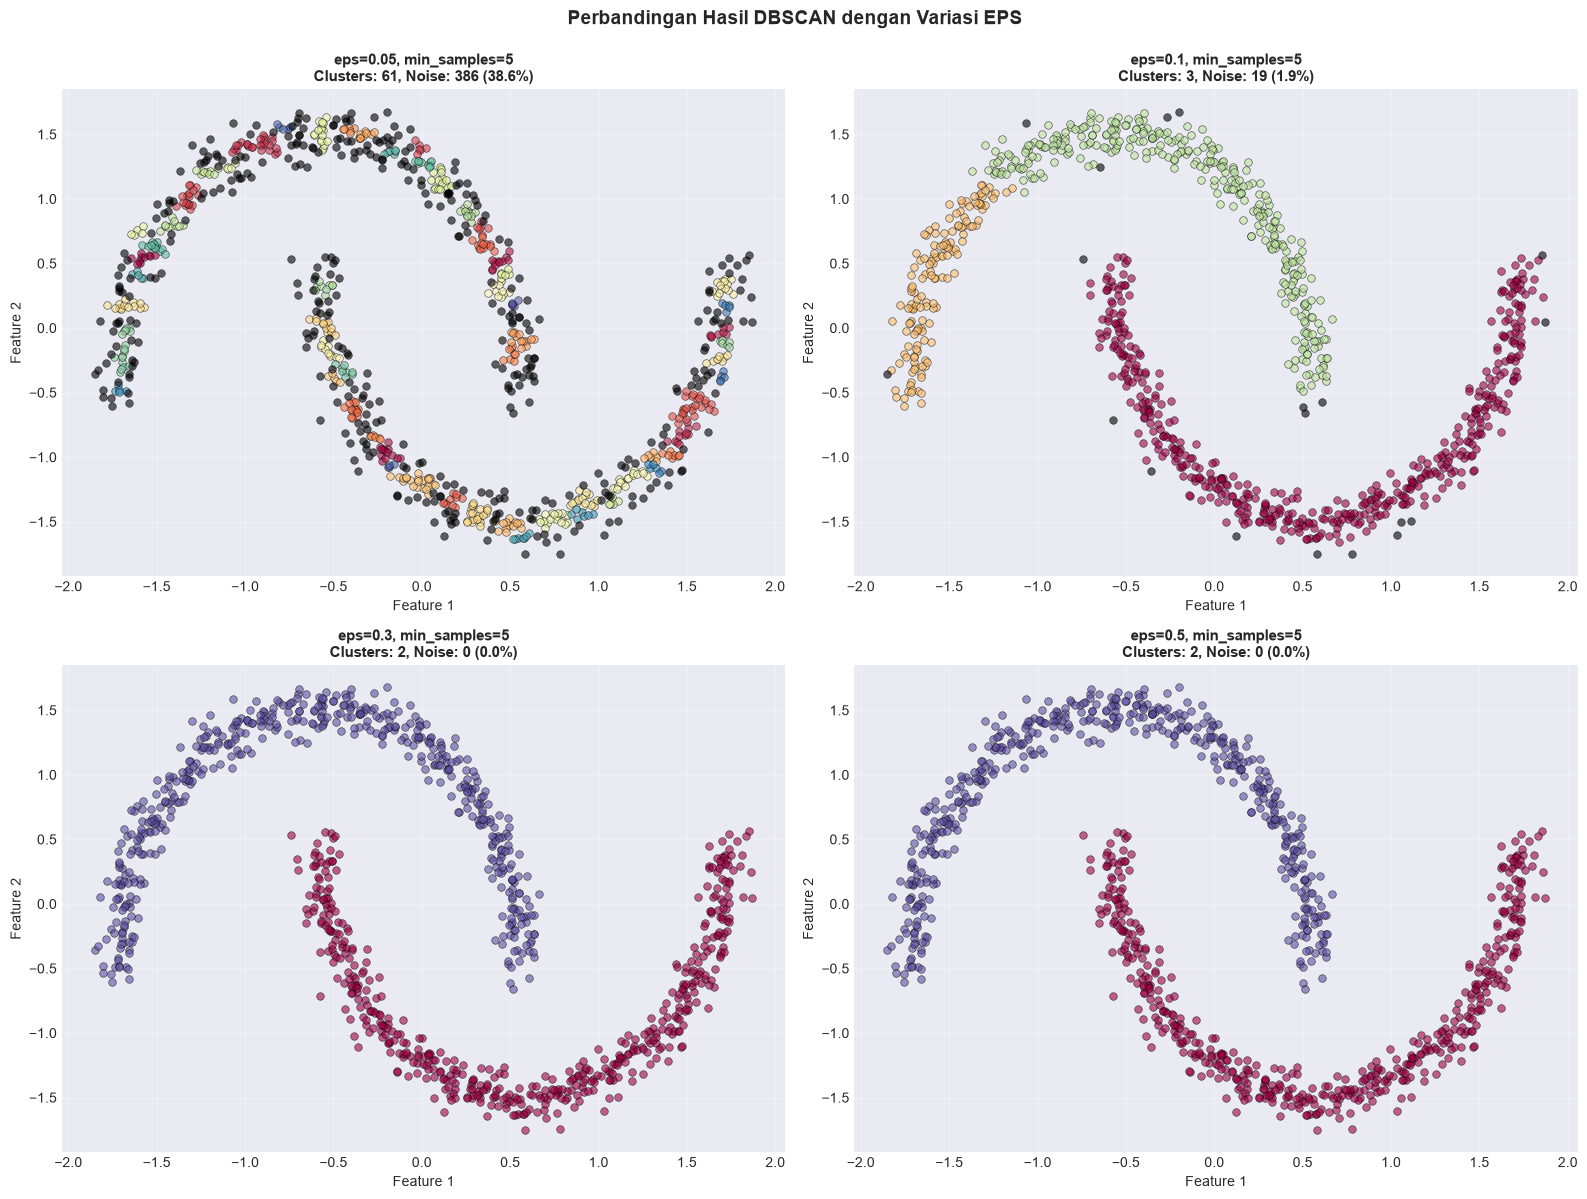

In [20]:
# Visualisasi perbandingan hasil eksperimen eps
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for idx, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=5)
    y_pred = dbscan.fit_predict(X_moons_scaled)
    
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
    n_noise = list(y_pred).count(-1)
    
    # Plot
    unique_labels = set(y_pred)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        
        class_member_mask = (y_pred == k)
        xy = X_moons_scaled[class_member_mask]
        axes[idx].scatter(xy[:, 0], xy[:, 1], c=[col], s=30, alpha=0.6, edgecolors='black', linewidth=0.5)
    
    axes[idx].set_title(f'eps={eps}, min_samples=5\nClusters: {n_clusters}, Noise: {n_noise} ({n_noise/len(X_moons_scaled)*100:.1f}%)', 
                       fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Perbandingan Hasil DBSCAN dengan Variasi EPS', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

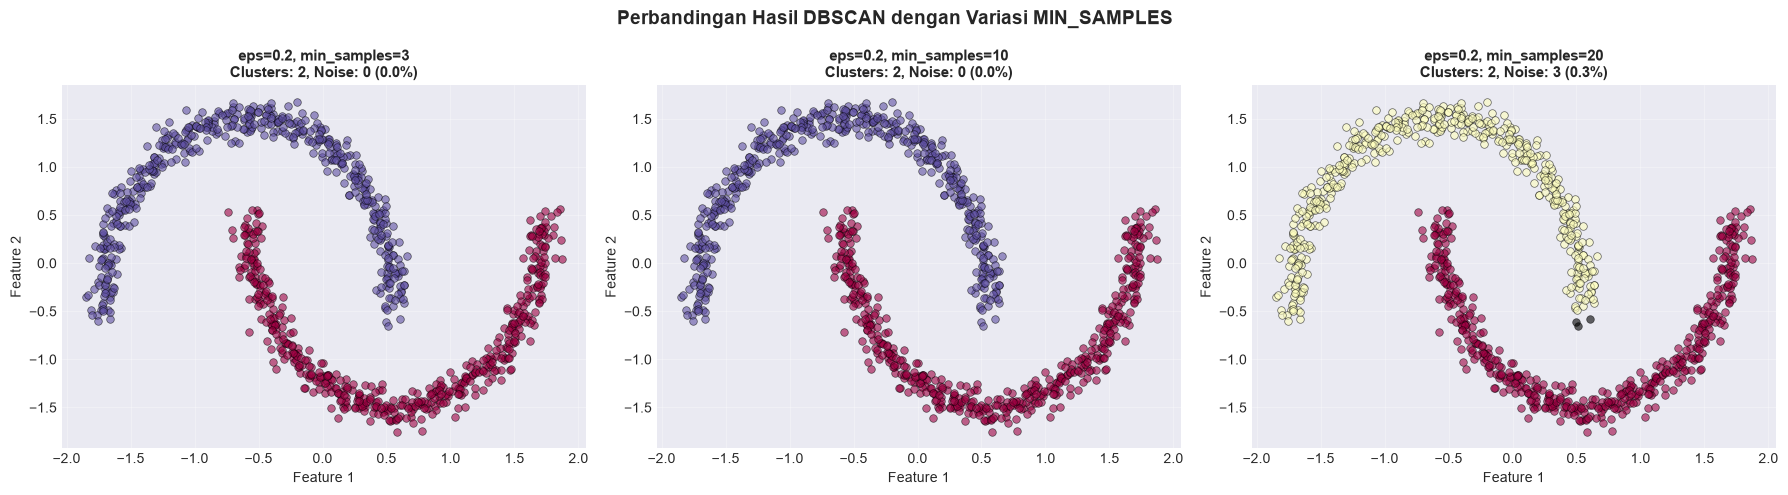

In [21]:
# Visualisasi perbandingan hasil eksperimen min_samples
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, min_samp in enumerate(min_samples_values):
    dbscan = DBSCAN(eps=0.2, min_samples=min_samp)
    y_pred = dbscan.fit_predict(X_moons_scaled)
    
    n_clusters = len(set(y_pred)) - (1 if -1 in y_pred else 0)
    n_noise = list(y_pred).count(-1)
    
    # Plot
    unique_labels = set(y_pred)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))
    
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        
        class_member_mask = (y_pred == k)
        xy = X_moons_scaled[class_member_mask]
        axes[idx].scatter(xy[:, 0], xy[:, 1], c=[col], s=30, alpha=0.6, edgecolors='black', linewidth=0.5)
    
    axes[idx].set_title(f'eps=0.2, min_samples={min_samp}\nClusters: {n_clusters}, Noise: {n_noise} ({n_noise/len(X_moons_scaled)*100:.1f}%)', 
                       fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Feature 1')
    axes[idx].set_ylabel('Feature 2')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Perbandingan Hasil DBSCAN dengan Variasi MIN_SAMPLES', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.6 Tabel Ringkasan Hasil Eksperimen

In [22]:
# Tabel ringkasan eksperimen eps
df_eps = pd.DataFrame(results_eps)
print("\n" + "="*80)
print("RINGKASAN EKSPERIMEN VARIASI EPS")
print("="*80)
print(df_eps.to_string(index=False))

# Tabel ringkasan eksperimen min_samples
df_min_samples = pd.DataFrame(results_min_samples)
print("\n" + "="*80)
print("RINGKASAN EKSPERIMEN VARIASI MIN_SAMPLES")
print("="*80)
print(df_min_samples.to_string(index=False))


RINGKASAN EKSPERIMEN VARIASI EPS
 eps  min_samples  n_clusters  n_noise  noise_pct  homogeneity  completeness  v_measure      ari      ami  silhouette
0.05            5          61      386       38.6          1.0      0.173551   0.295771 0.038512 0.279373    0.501707
0.10            5           3       19        1.9          1.0      0.693244   0.818835 0.788126 0.818616    0.377767
0.30            5           2        0        0.0          1.0      1.000000   1.000000 1.000000 1.000000    0.391160
0.50            5           2        0        0.0          1.0      1.000000   1.000000 1.000000 1.000000    0.391160

RINGKASAN EKSPERIMEN VARIASI MIN_SAMPLES
 eps  min_samples  n_clusters  n_noise  noise_pct  homogeneity  completeness  v_measure  ari  ami  silhouette
 0.2            3           2        0        0.0          1.0           1.0        1.0  1.0  1.0    0.391160
 0.2           10           2        0        0.0          1.0           1.0        1.0  1.0  1.0    0.391160
 0.2

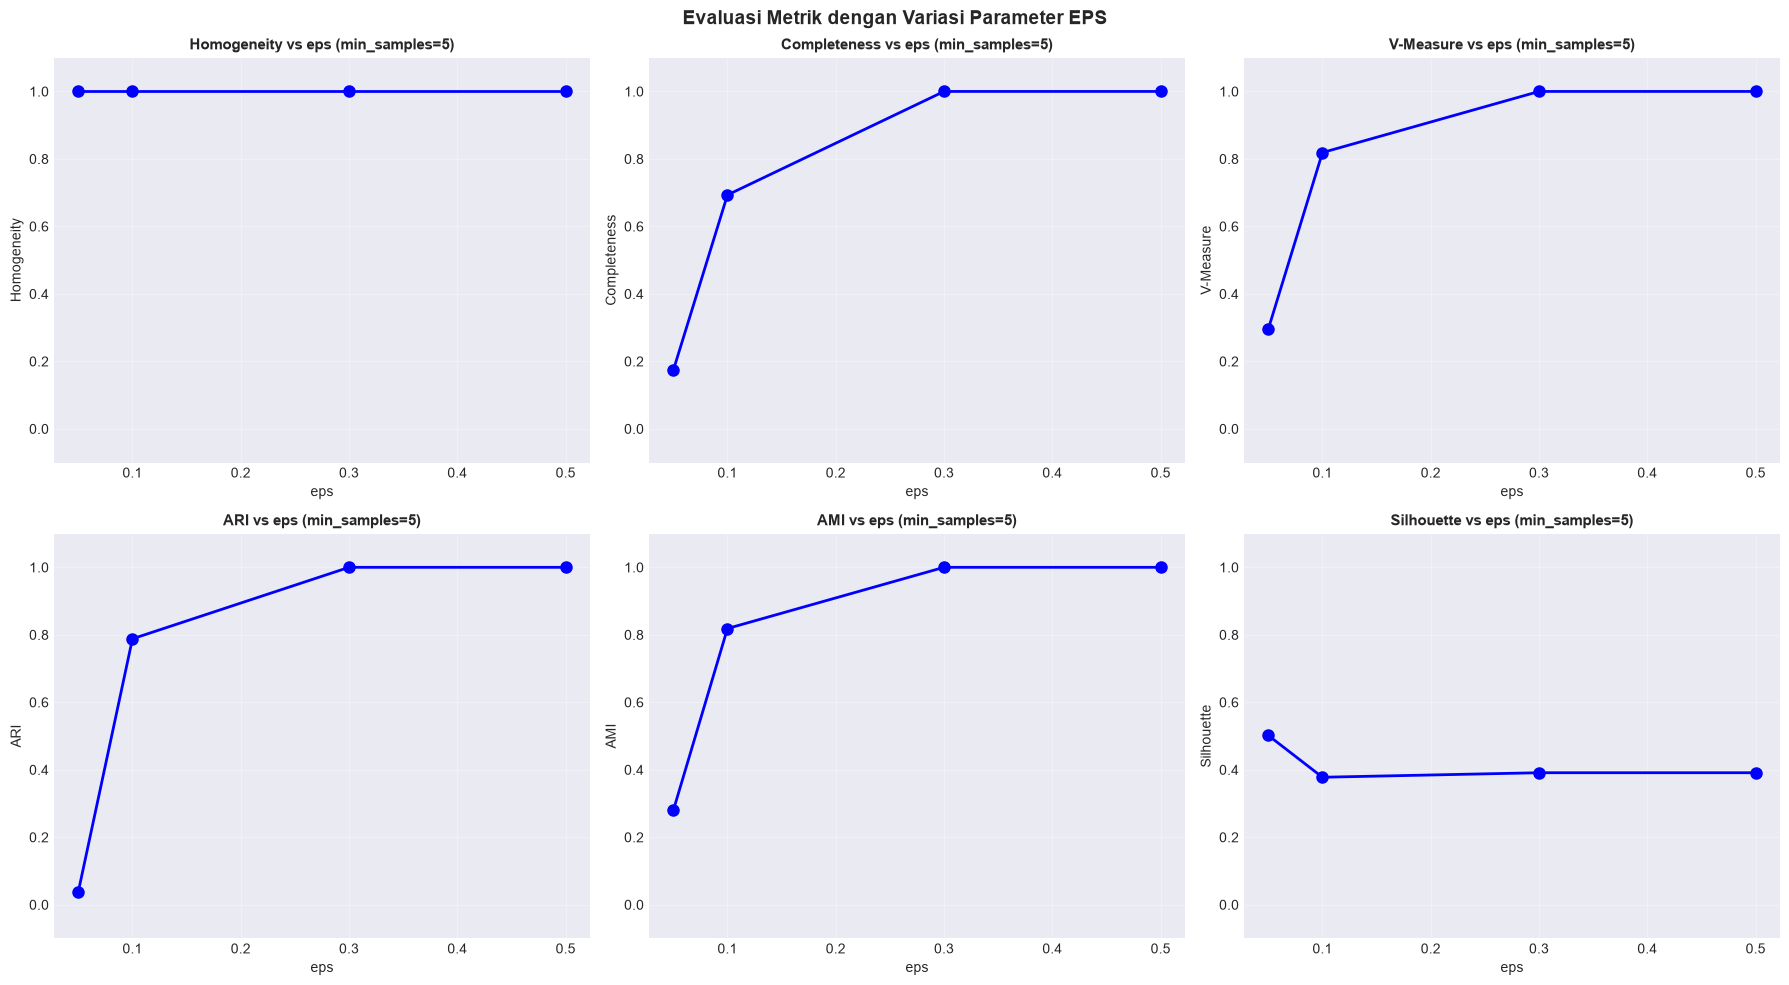

In [23]:
# Visualisasi metrik evaluasi dalam bentuk grafik
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

metrics_to_plot = ['homogeneity', 'completeness', 'v_measure', 'ari', 'ami', 'silhouette']
metric_names = ['Homogeneity', 'Completeness', 'V-Measure', 'ARI', 'AMI', 'Silhouette']

for idx, (metric, name) in enumerate(zip(metrics_to_plot, metric_names)):
    row = idx // 3
    col = idx % 3
    
    # Plot variasi eps
    axes[row, col].plot([r['eps'] for r in results_eps], 
                       [r[metric] for r in results_eps], 
                       'bo-', linewidth=2, markersize=8, label='Variasi eps')
    
    axes[row, col].set_xlabel('eps', fontsize=10)
    axes[row, col].set_ylabel(name, fontsize=10)
    axes[row, col].set_title(f'{name} vs eps (min_samples=5)', fontsize=11, fontweight='bold')
    axes[row, col].grid(True, alpha=0.3)
    axes[row, col].set_ylim([-0.1, 1.1])

plt.suptitle('Evaluasi Metrik dengan Variasi Parameter EPS', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.7 Kesimpulan

**Pengaruh Parameter EPS:**
- **eps kecil (0.05, 0.1)**: Menghasilkan banyak noise dan cluster kecil-kecil
- **eps optimal (0.2, 0.3)**: Menghasilkan clustering yang baik dengan 2 cluster yang sesuai ground truth
- **eps besar (0.5)**: Cenderung menggabungkan cluster yang seharusnya terpisah

**Pengaruh Parameter MIN_SAMPLES:**
- **min_samples kecil (3)**: Lebih sedikit noise, tapi cluster bisa kurang stabil
- **min_samples sedang (5, 10)**: Memberikan keseimbangan yang baik
- **min_samples besar (20)**: Banyak titik dianggap noise, cluster lebih ketat

**Parameter Terbaik:**
Untuk dataset make_moons ini, kombinasi **eps=0.2** dan **min_samples=5** memberikan hasil terbaik dengan:
- 2 cluster yang terdeteksi (sesuai ground truth)
- Noise yang minimal
- Nilai metrik evaluasi yang tinggi